## 1. Install required libraries

In [1]:
!pip -q install huggingface_hub pillow pandas numpy matplotlib seaborn


## 2. Import libraries

In [2]:
import os, json, random
from collections import Counter
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image, ImageDraw
from huggingface_hub import hf_hub_download, list_repo_files

sns.set_theme(style="whitegrid")
random.seed(42)
np.random.seed(42)


## 3. Download COCO annotations

In [3]:
REPO_ID = "iisc-aim/BMD-45"
REPO_TYPE = "dataset"
TRAIN_FOLDER = "BMD-45-Train"

annotation_path = hf_hub_download(
    repo_id=REPO_ID,
    filename=f"{TRAIN_FOLDER}/_annotations.coco.json",
    repo_type=REPO_TYPE
)

with open(annotation_path, "r") as f:
    coco_data = json.load(f)

print("COCO annotation file downloaded successfully!")
print("Images listed:", len(coco_data.get("images", [])))
print("Annotations:", len(coco_data.get("annotations", [])))
print("Categories:", len(coco_data.get("categories", [])))


BMD-45-Train/_annotations.coco.json: reconstructing file:   0%|          |  0.00B / 49.4MB            

BMD-45-Train/_annotations.coco.json: downloading bytes:           |  0.00B            

COCO annotation file downloaded successfully!
Images listed: 35792
Annotations: 373132
Categories: 13


## 4. Inspect repository and select up to 100 images

In [4]:
repo_files = list_repo_files(repo_id=REPO_ID, repo_type=REPO_TYPE)
image_records = coco_data.get("images", [])
if not image_records:
    raise ValueError("No image records found in the COCO annotation file.")

selected_images = random.sample(image_records, min(100, len(image_records)))
selected_image_ids = {img["id"] for img in selected_images}

print("Selected images:", len(selected_images))
print("Example image record:", selected_images[0])
print("Example repository files:", repo_files[:15])


Selected images: 100
Example image record: {'file_name': 'images_001/201438.png', 'height': 1080, 'id': 10371, 'width': 1920}
Example repository files: ['.gitattributes', 'BMD-45-Train/_annotations.coco.json', 'BMD-45-Train/images_000/10009.png', 'BMD-45-Train/images_000/100093.png', 'BMD-45-Train/images_000/100095.png', 'BMD-45-Train/images_000/100115.png', 'BMD-45-Train/images_000/100130.png', 'BMD-45-Train/images_000/100173.png', 'BMD-45-Train/images_000/100201.png', 'BMD-45-Train/images_000/10023.png', 'BMD-45-Train/images_000/100260.png', 'BMD-45-Train/images_000/100296.png', 'BMD-45-Train/images_000/100331.png', 'BMD-45-Train/images_000/100355.png', 'BMD-45-Train/images_000/100375.png']


## 5. Download only the selected images

In [5]:
IMAGE_DIR = "/content/BMD45_selected_images"
os.makedirs(IMAGE_DIR, exist_ok=True)
repo_file_set = set(repo_files)
image_paths = {}

def find_repo_image_path(file_name):
    candidates = [f"{TRAIN_FOLDER}/{file_name}", file_name]
    for candidate in candidates:
        if candidate in repo_file_set:
            return candidate
    matches = [p for p in repo_files if p.endswith("/" + file_name) or p == file_name]
    if matches:
        return matches[0]
    raise FileNotFoundError(f"Could not find '{file_name}' in the repository.")

for i, img_info in enumerate(selected_images, start=1):
    repo_path = find_repo_image_path(img_info["file_name"])
    local_path = hf_hub_download(
        repo_id=REPO_ID,
        filename=repo_path,
        repo_type=REPO_TYPE,
        local_dir=IMAGE_DIR
    )
    image_paths[img_info["id"]] = local_path
    if i % 10 == 0 or i == len(selected_images):
        print(f"Downloaded {i}/{len(selected_images)} images")

print("Image download completed.")


BMD-45-Train/images_001/201438.png: reconstructing file:   0%|          |  0.00B / 3.49MB            

BMD-45-Train/images_001/201438.png: downloading bytes:           |  0.00B            

BMD-45-Train/images_000/44432.png: reconstructing file:   0%|          |  0.00B / 2.86MB            

BMD-45-Train/images_000/44432.png: downloading bytes:           |  0.00B            

BMD-45-Train/images_003/506588.png: reconstructing file:   0%|          |  0.00B / 3.39MB            

BMD-45-Train/images_003/506588.png: downloading bytes:           |  0.00B            

... (200 outputs left out)

BMD-45-Train/images_006/904573.png: downloading bytes:           |  0.00B            

BMD-45-Train/images_001/163011.png: reconstructing file:   0%|          |  0.00B / 2.44MB            

BMD-45-Train/images_001/163011.png: downloading bytes:           |  0.00B            

Downloaded 100/100 images
Image download completed.


## 6. Display 10 different sample images

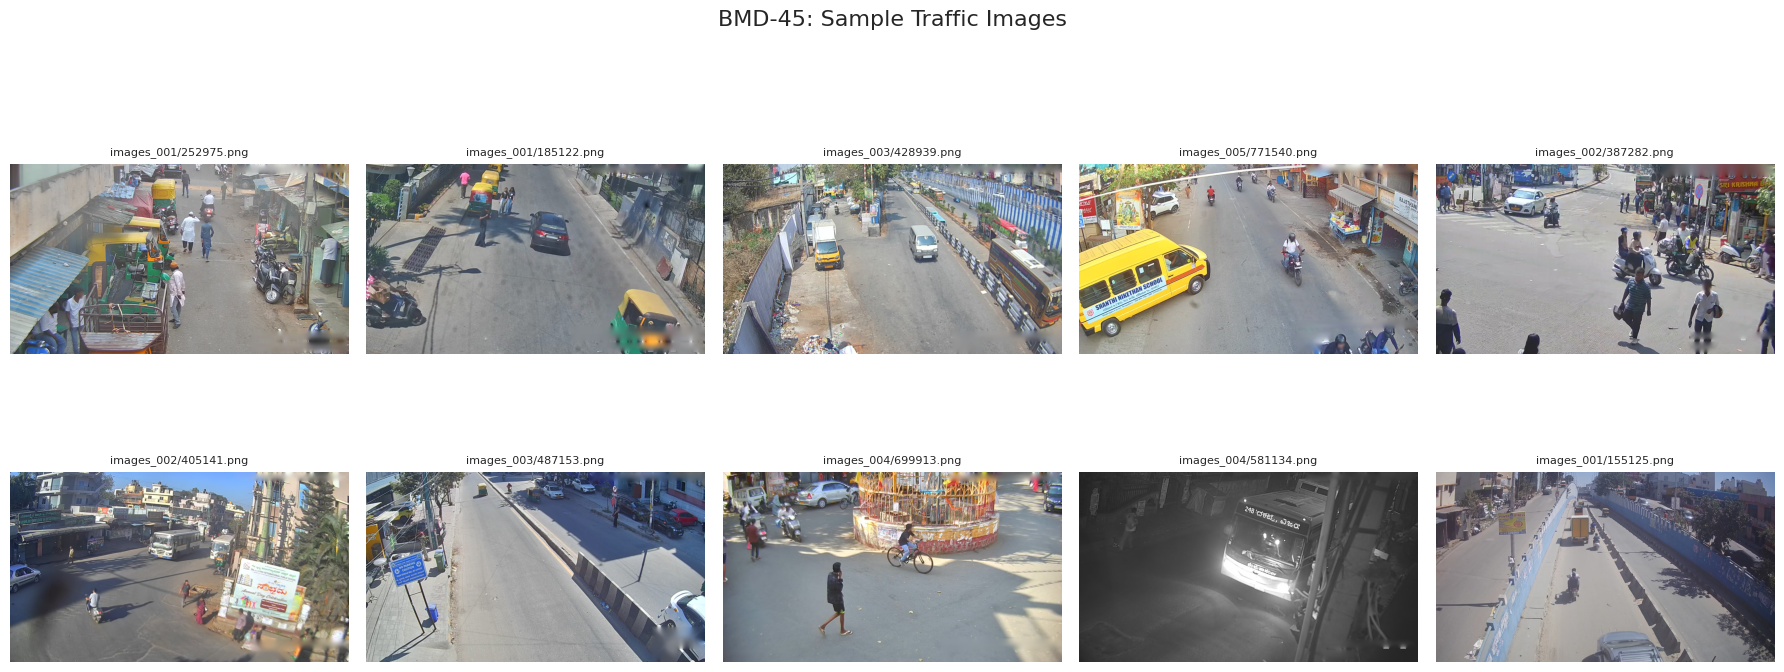

In [6]:
sample_to_display = random.sample(selected_images, min(10, len(selected_images)))
fig, axes = plt.subplots(2, 5, figsize=(18, 8))
axes = axes.flatten()

for ax, img_info in zip(axes, sample_to_display):
    image = Image.open(image_paths[img_info["id"]]).convert("RGB")
    ax.imshow(image)
    ax.set_title(img_info["file_name"], fontsize=8)
    ax.axis("off")

for ax in axes[len(sample_to_display):]:
    ax.axis("off")

plt.suptitle("BMD-45: Sample Traffic Images", fontsize=16)
plt.tight_layout()
plt.show()


## 7. Explore COCO categories and annotations

In [7]:
selected_annotations = [
    ann for ann in coco_data.get("annotations", [])
    if ann.get("image_id") in selected_image_ids
]
categories = coco_data.get("categories", [])
category_name = {cat["id"]: cat["name"] for cat in categories}

print("Selected images:", len(selected_images))
print("Annotations for selected images:", len(selected_annotations))
print("Categories in COCO file:", len(categories))
print("\nCategory names:")
for cat in categories:
    print(f'{cat["id"]}: {cat["name"]}')
print("\nExample annotation:")
print(selected_annotations[0] if selected_annotations else "No annotations found.")


Selected images: 100
Annotations for selected images: 1030
Categories in COCO file: 13

Category names:
0: Hatchback
1: Sedan
2: SUV
3: MUV
4: Bus
5: Truck
6: Three-wheeler
7: Two-wheeler
8: LCV
9: Mini-bus
10: Tempo-traveller
11: Bicycle
12: Van

Example annotation:
{'area': 84480, 'bbox': [1563.4399999999998, 177.94999999999996, 330, 255.99999999999997], 'category_id': 0, 'id': 7398, 'image_id': 628, 'iscrowd': 0}


## 8. Create a bounding-box table

In [8]:
annotation_rows = []
for ann in selected_annotations:
    x, y, width, height = ann["bbox"]  # COCO: [x, y, width, height]
    annotation_rows.append({
        "image_id": ann["image_id"],
        "category_id": ann["category_id"],
        "category": category_name.get(ann["category_id"], "Unknown"),
        "x": x, "y": y, "width": width, "height": height,
        "bbox_area": width * height,
        "annotation_area": ann.get("area", width * height)
    })

bbox_df = pd.DataFrame(annotation_rows)
display(bbox_df.head(10))
if bbox_df.empty:
    raise ValueError("No bounding-box annotations found for the selected images.")


,image_id,category_id,category,x,y,width,height,bbox_area,annotation_area
0,628,0,Hatchback,1563.440000,177.950000,330.00,256.000000,84480.000000,84480.000000
1,628,0,Hatchback,1332.860000,16.290000,272.00,201.000000,54672.000000,54672.000000
2,628,7,Two-wheeler,0.000000,687.260000,64.70,122.000000,7893.400000,7930.000000
3,2355,8,LCV,940.066667,1.006667,231.00,168.000000,38808.000000,38808.000000
4,2355,1,Sedan,1611.250000,102.020000,129.00,152.000000,19608.000000,19608.000000
5,2355,12,Van,1740.200000,55.596667,125.00,171.666667,21458.333333,21458.333333
6,2355,5,Truck,0.000000,6.260000,228.63,570.000000,130319.100000,130530.000000
7,2494,6,Three-wheeler,928.120000,128.380000,118.00,109.000000,12862.000000,12862.000000
8,2494,6,Three-wheeler,1054.950000,152.460000,101.00,135.000000,13635.000000,13635.000000
9,2494,6,Three-wheeler,534.460000,120.430000,92.00,93.000000,8556.000000,8556.000000


## 9. Category distribution – bar graph

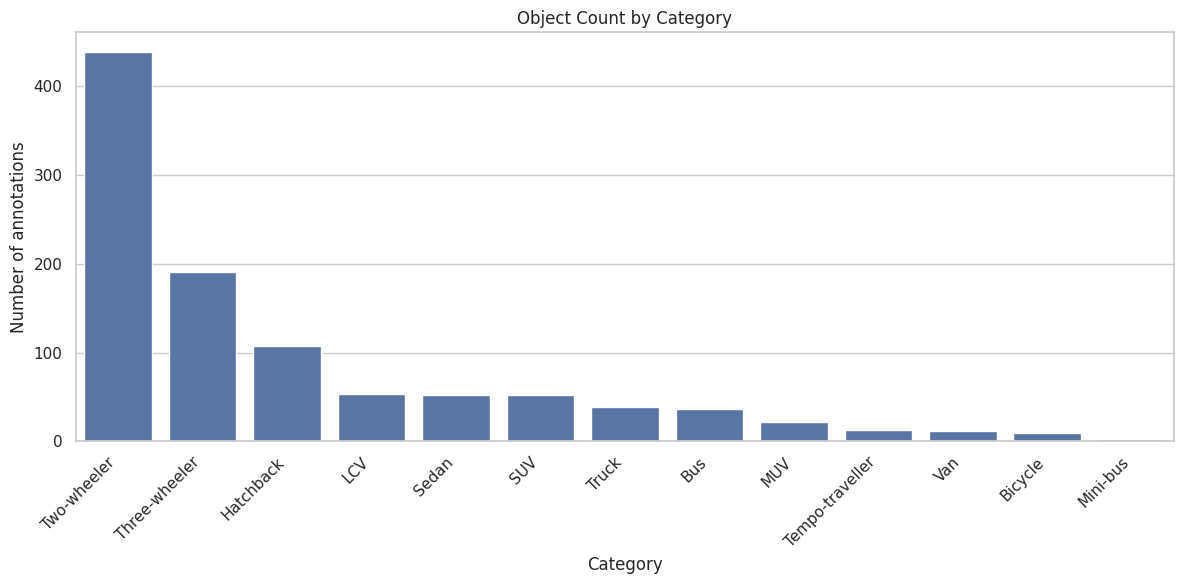

,category,count
0,Two-wheeler,439
1,Three-wheeler,191
2,Hatchback,108
3,LCV,53
4,Sedan,52
5,SUV,52
6,Truck,39
7,Bus,37
8,MUV,22
9,Tempo-traveller,13


In [9]:
category_counts = bbox_df["category"].value_counts().rename_axis("category").reset_index(name="count")
plt.figure(figsize=(12, 6))
sns.barplot(data=category_counts, x="category", y="count")
plt.title("Object Count by Category")
plt.xlabel("Category")
plt.ylabel("Number of annotations")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()
display(category_counts)


## 10. Category distribution – pie chart

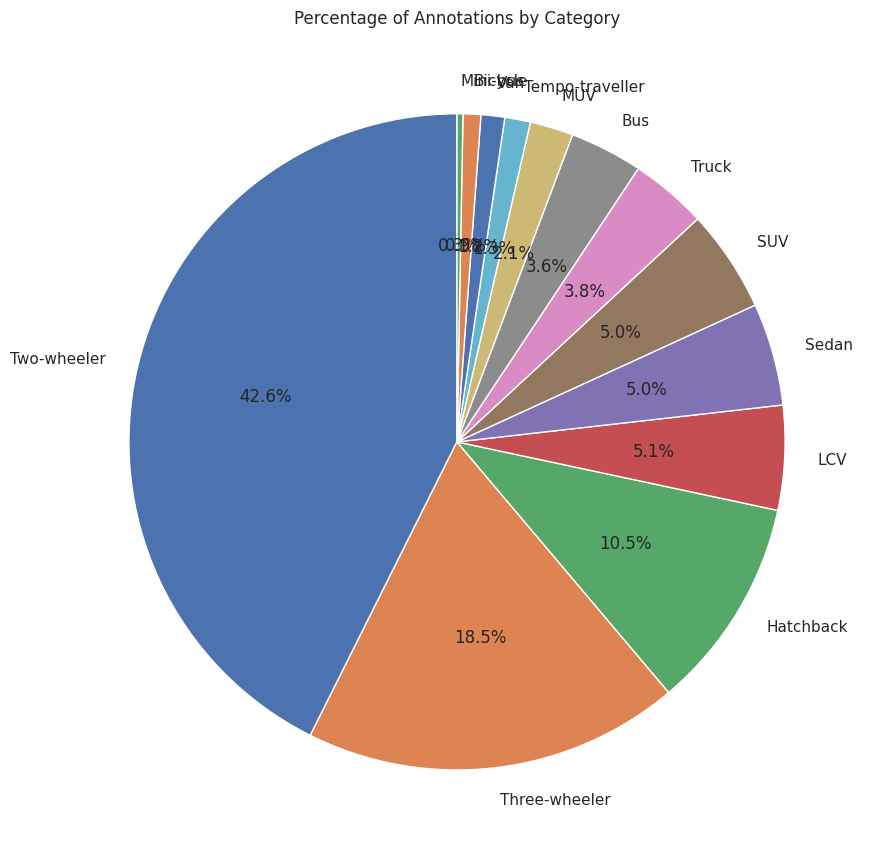

In [10]:
plt.figure(figsize=(9, 9))
plt.pie(category_counts["count"], labels=category_counts["category"],
        autopct="%1.1f%%", startangle=90)
plt.title("Percentage of Annotations by Category")
plt.tight_layout()
plt.show()


## 11. Visualize bounding boxes and category labels

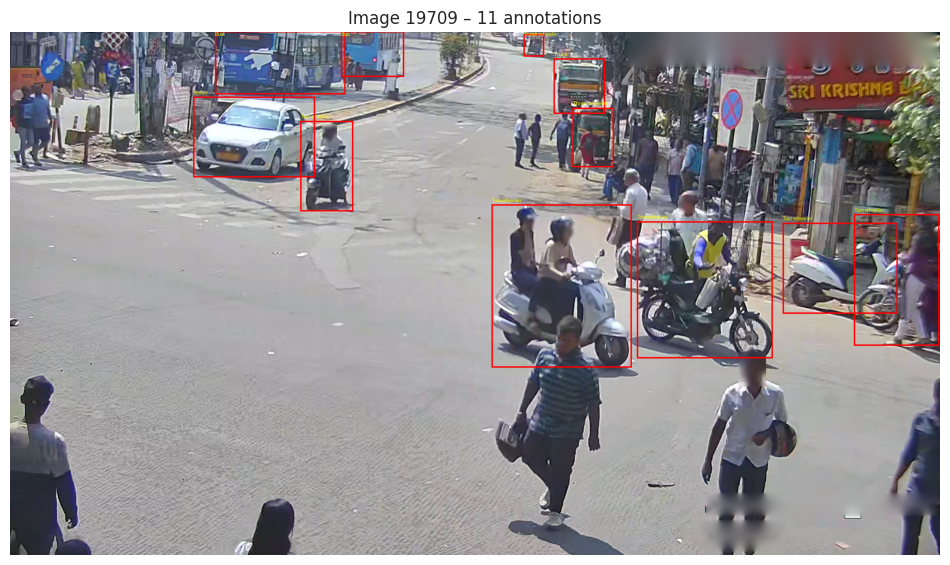

In [11]:
def show_bounding_boxes(image_id):
    img_info = next(img for img in selected_images if img["id"] == image_id)
    image = Image.open(image_paths[image_id]).convert("RGB")
    draw = ImageDraw.Draw(image)
    anns = [ann for ann in selected_annotations if ann["image_id"] == image_id]

    for ann in anns:
        x, y, width, height = ann["bbox"]
        label = category_name.get(ann["category_id"], "Unknown")
        draw.rectangle([x, y, x + width, y + height], outline="red", width=3)
        draw.text((x, max(0, y - 15)), label, fill="yellow")

    plt.figure(figsize=(12, 8))
    plt.imshow(image)
    plt.title(f"Image {image_id} – {len(anns)} annotations")
    plt.axis("off")
    plt.show()

images_with_annotations = [
    img_id for img_id in selected_image_ids
    if any(a["image_id"] == img_id for a in selected_annotations)
]
if images_with_annotations:
    show_bounding_boxes(random.choice(images_with_annotations))
else:
    print("No selected image has bounding-box annotations.")


## 12. Compare images with fewer and more objects

Image with fewest annotations: 25293


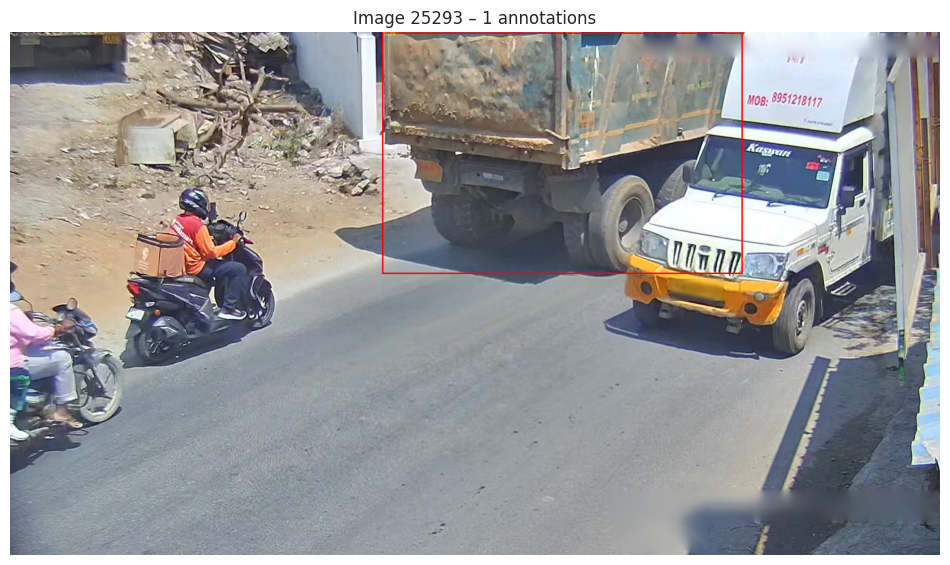

Image with most annotations: 42435


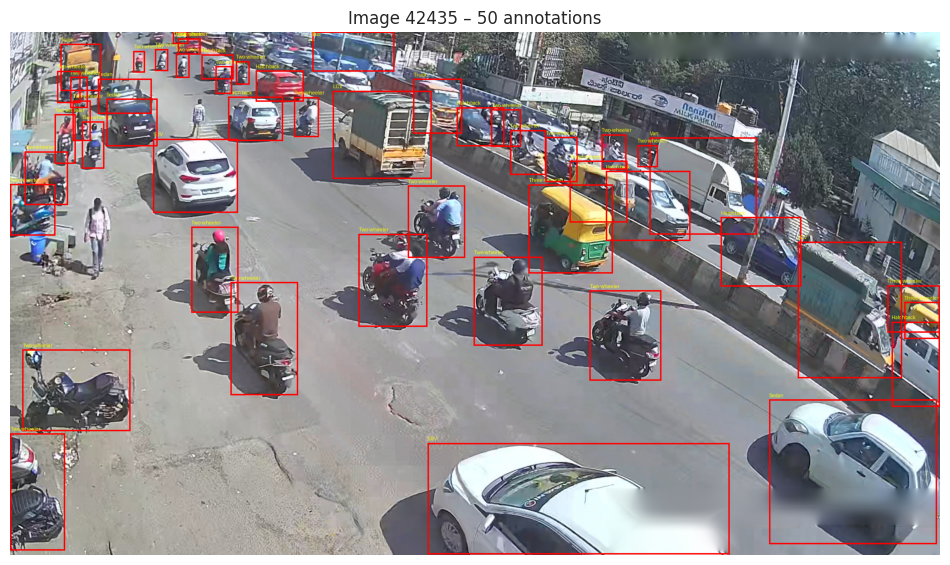

In [12]:
objects_per_image = pd.Series(
    [ann["image_id"] for ann in selected_annotations]
).value_counts().rename_axis("image_id").reset_index(name="object_count")

all_image_counts = pd.DataFrame({"image_id": list(selected_image_ids)})
objects_per_image = all_image_counts.merge(objects_per_image, on="image_id", how="left")
objects_per_image["object_count"] = objects_per_image["object_count"].fillna(0).astype(int)

fewest_id = int(objects_per_image.sort_values("object_count").iloc[0]["image_id"])
most_id = int(objects_per_image.sort_values("object_count", ascending=False).iloc[0]["image_id"])

print("Image with fewest annotations:", fewest_id)
show_bounding_boxes(fewest_id)
print("Image with most annotations:", most_id)
show_bounding_boxes(most_id)


## 13. Number of objects per image – histogram

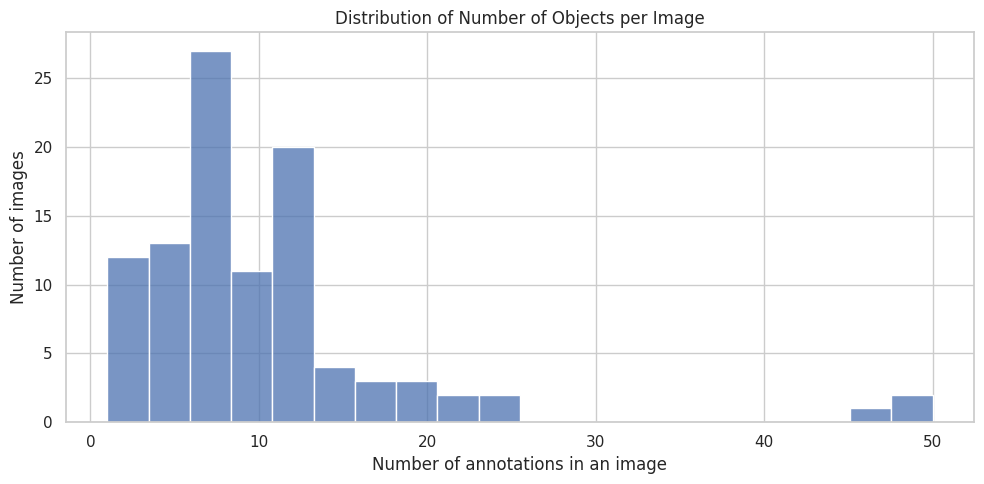

In [13]:
plt.figure(figsize=(10, 5))
sns.histplot(objects_per_image["object_count"], bins=20)
plt.title("Distribution of Number of Objects per Image")
plt.xlabel("Number of annotations in an image")
plt.ylabel("Number of images")
plt.tight_layout()
plt.show()


## 14. Bounding-box width distribution

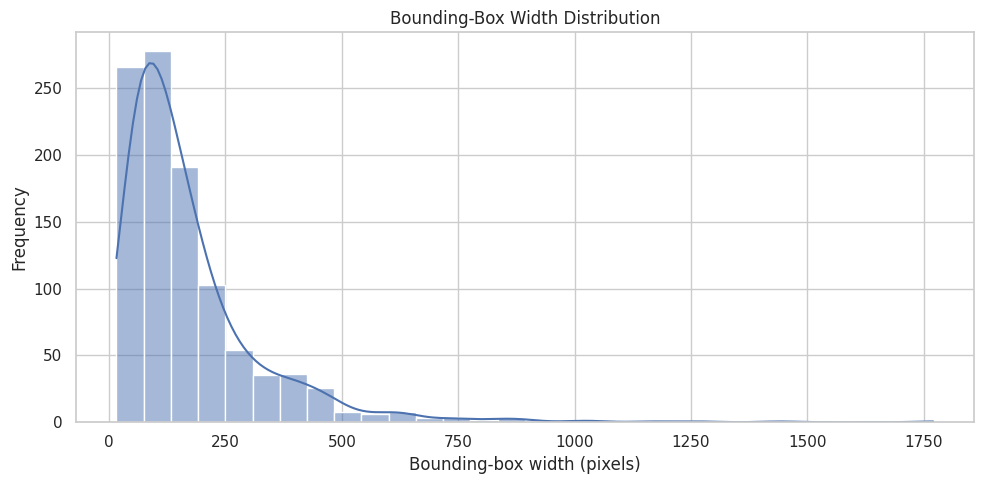

In [14]:
plt.figure(figsize=(10, 5))
sns.histplot(bbox_df["width"], bins=30, kde=True)
plt.title("Bounding-Box Width Distribution")
plt.xlabel("Bounding-box width (pixels)")
plt.ylabel("Frequency")
plt.tight_layout()
plt.show()


## 15. Bounding-box height distribution

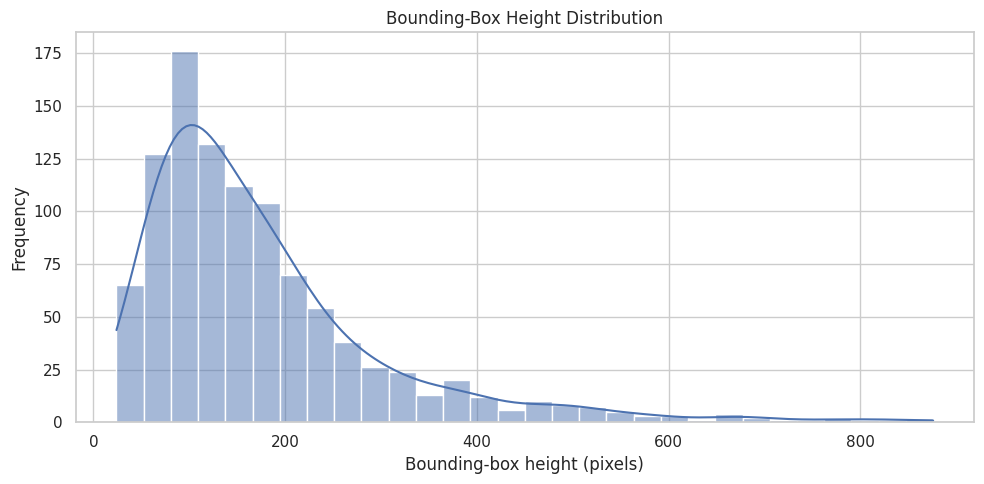

In [15]:
plt.figure(figsize=(10, 5))
sns.histplot(bbox_df["height"], bins=30, kde=True)
plt.title("Bounding-Box Height Distribution")
plt.xlabel("Bounding-box height (pixels)")
plt.ylabel("Frequency")
plt.tight_layout()
plt.show()


## 16. Bounding-box area distribution

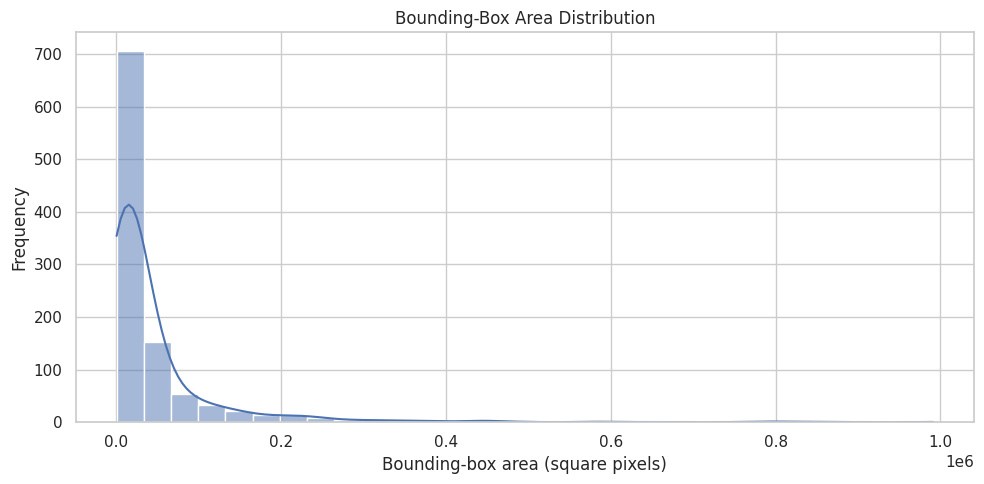

In [16]:
plt.figure(figsize=(10, 5))
sns.histplot(bbox_df["bbox_area"], bins=30, kde=True)
plt.title("Bounding-Box Area Distribution")
plt.xlabel("Bounding-box area (square pixels)")
plt.ylabel("Frequency")
plt.tight_layout()
plt.show()


## 17. Bounding-box width vs height

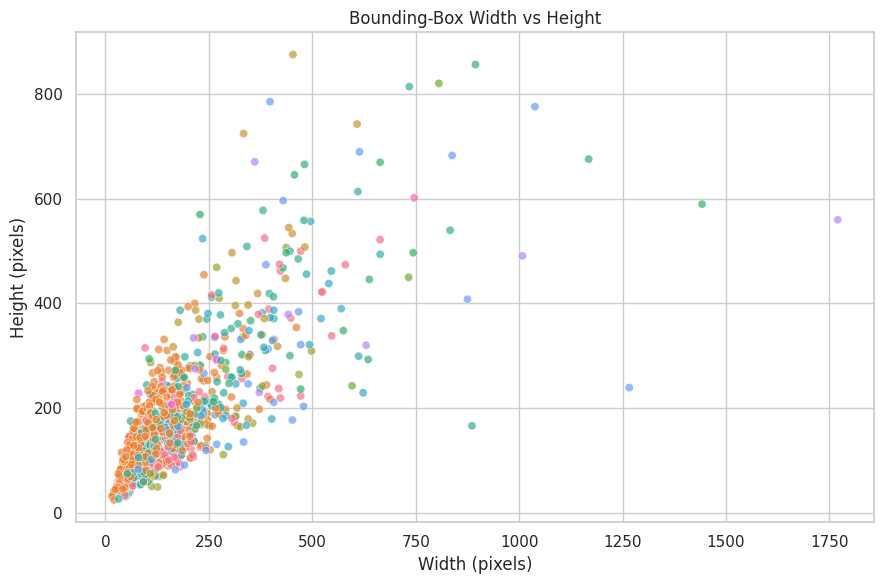

In [17]:
plt.figure(figsize=(9, 6))
sns.scatterplot(data=bbox_df, x="width", y="height", hue="category",
                legend=False, alpha=0.7)
plt.title("Bounding-Box Width vs Height")
plt.xlabel("Width (pixels)")
plt.ylabel("Height (pixels)")
plt.tight_layout()
plt.show()


## 18. Category-wise bounding-box area comparison

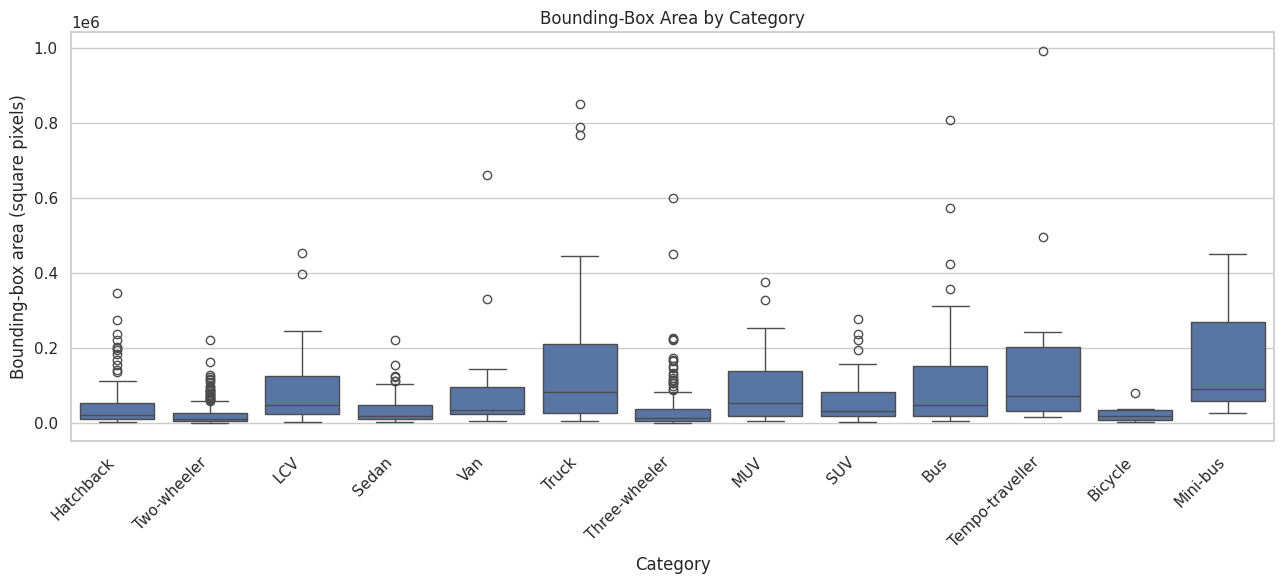

In [18]:
plt.figure(figsize=(13, 6))
sns.boxplot(data=bbox_df, x="category", y="bbox_area")
plt.title("Bounding-Box Area by Category")
plt.xlabel("Category")
plt.ylabel("Bounding-box area (square pixels)")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()


## 19. Bounding-box aspect ratio

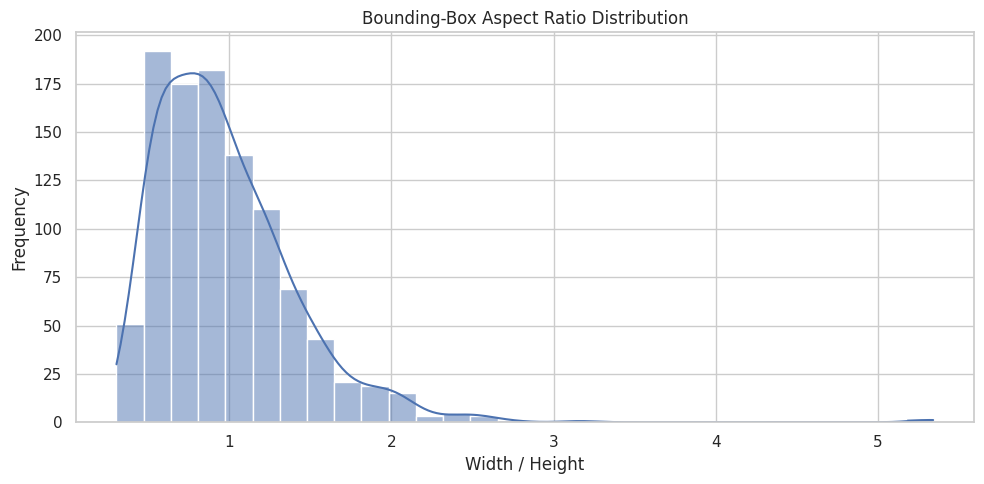

In [19]:
bbox_df["aspect_ratio"] = bbox_df["width"] / bbox_df["height"].replace(0, np.nan)
plt.figure(figsize=(10, 5))
sns.histplot(bbox_df["aspect_ratio"].dropna(), bins=30, kde=True)
plt.title("Bounding-Box Aspect Ratio Distribution")
plt.xlabel("Width / Height")
plt.ylabel("Frequency")
plt.tight_layout()
plt.show()


## 20. Image dimensions

,image_id,file_name,image_width,image_height
0,10371,images_001/201438.png,1920,1080
1,2355,images_000/44432.png,1920,1080
2,25769,images_003/506588.png,1920,1080
3,22916,images_003/450933.png,1920,1080
4,20855,images_002/410327.png,1920,1080


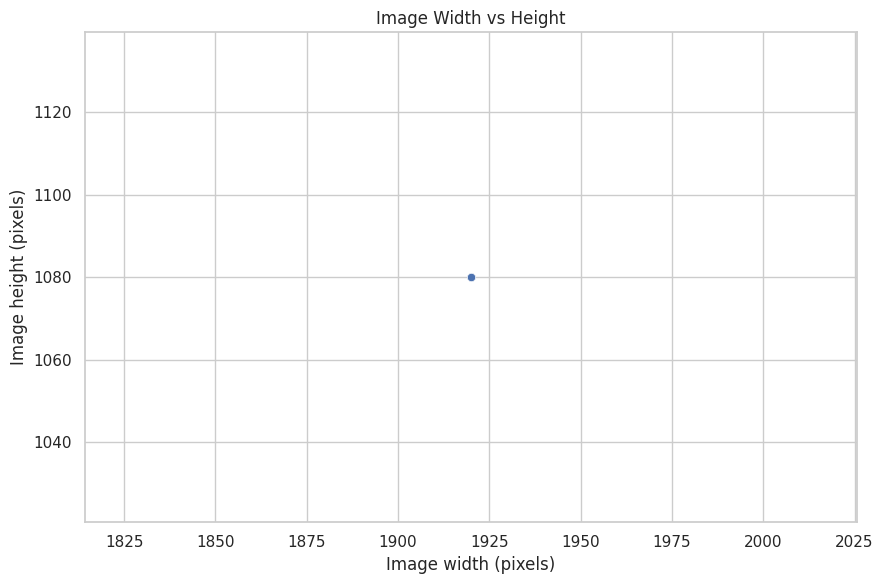

In [20]:
dimensions_df = pd.DataFrame([
    {
        "image_id": img["id"],
        "file_name": img["file_name"],
        "image_width": img["width"],
        "image_height": img["height"]
    }
    for img in selected_images
])
display(dimensions_df.head())

plt.figure(figsize=(9, 6))
sns.scatterplot(data=dimensions_df, x="image_width", y="image_height")
plt.title("Image Width vs Height")
plt.xlabel("Image width (pixels)")
plt.ylabel("Image height (pixels)")
plt.tight_layout()
plt.show()


## 21. Small, medium and large bounding-box counts

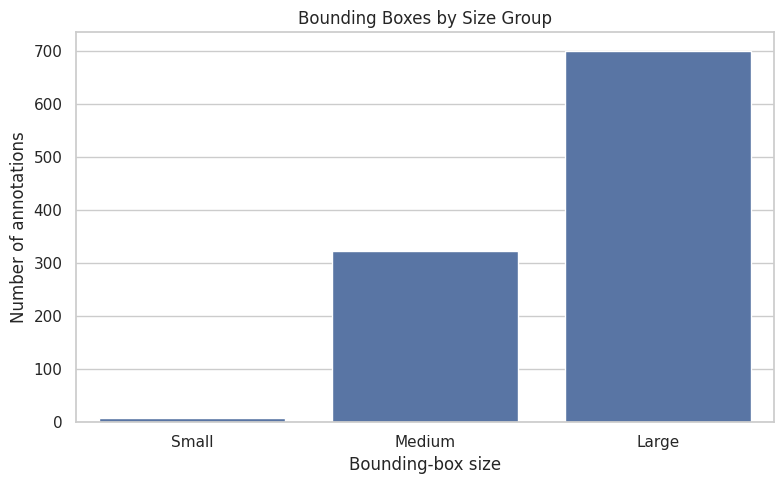

,size_group,count
0,Small,8
1,Medium,322
2,Large,700


In [21]:
bbox_df["size_group"] = pd.cut(
    bbox_df["bbox_area"],
    bins=[-np.inf, 32**2, 96**2, np.inf],
    labels=["Small", "Medium", "Large"]
)
size_counts = bbox_df["size_group"].value_counts().reindex(
    ["Small", "Medium", "Large"], fill_value=0
).reset_index()
size_counts.columns = ["size_group", "count"]

plt.figure(figsize=(8, 5))
sns.barplot(data=size_counts, x="size_group", y="count")
plt.title("Bounding Boxes by Size Group")
plt.xlabel("Bounding-box size")
plt.ylabel("Number of annotations")
plt.tight_layout()
plt.show()
display(size_counts)


## 22. Final dataset summary

In [22]:
print("========== BMD-45 WEEK 5 SUMMARY ==========")
print("Images selected:", len(selected_images))
print("Annotations in selected images:", len(selected_annotations))
print("Categories listed in dataset:", len(categories))
print("Categories present in selected subset:", bbox_df["category"].nunique())
print("Average objects per selected image:",
      round(len(selected_annotations) / max(len(selected_images), 1), 2))
print("Average bounding-box width:", round(bbox_df["width"].mean(), 2))
print("Average bounding-box height:", round(bbox_df["height"].mean(), 2))
print("Average bounding-box area:", round(bbox_df["bbox_area"].mean(), 2))
print("\nCategory counts:")
display(category_counts)
print("========== EXPLORATION COMPLETED ==========")


========== BMD-45 WEEK 5 SUMMARY ==========
Images selected: 100
Annotations in selected images: 1030
Categories listed in dataset: 13
Categories present in selected subset: 13
Average objects per selected image: 10.3
Average bounding-box width: 173.09
Average bounding-box height: 176.66
Average bounding-box area: 46746.48

Category counts:


,category,count
0,Two-wheeler,439
1,Three-wheeler,191
2,Hatchback,108
3,LCV,53
4,Sedan,52
5,SUV,52
6,Truck,39
7,Bus,37
8,MUV,22
9,Tempo-traveller,13


========== EXPLORATION COMPLETED ==========
